# Librerías

In [ ]:
import numpy as np #paquete para manejar arreglos
from matplotlib import pyplot as plt #para graficar

# https://numpy.org/doc/stable/reference/routines.polynomials.classes.html
from numpy.polynomial import Polynomial as Poly #para interpolar

# Detalle técnico no relevante
plt.rcParams["figure.figsize"] = (8,5) #tamaño de los gráficos: ancho x alto

---
# Mínimos cuadrados **generalizado**

- ## Charlar la idea de mínimos cuadrados generalizado: se propone función y se minimiza error cuadrático _con pesos_.
- ## Tiene menor error cuadrático que el normal.

---

## Ejemplo  (regresión no lineal, transformación, cuadrados mínimos generalizado): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)=a\text{e}^{bx}$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos **generalizado**, resolviendo las ecuaciones normales.
  - ### Misma idea de resolución que antes, agregando los pesos: transformación y usar regresión lineal.
  - ### Los pesos son $w_i = \left(\dfrac{1}{h'(y_i)}\right)^2$, donde $h$ es la transformación de los $y$.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio. Comparar con cuadrados mínimos normal.
1. ### Ídem 1 con `numpy.polynomial`. Comparar que da igual.

[-2.36370136e+01  1.36066963e-02]
Error cuadrático medio: 0.48990303132111745


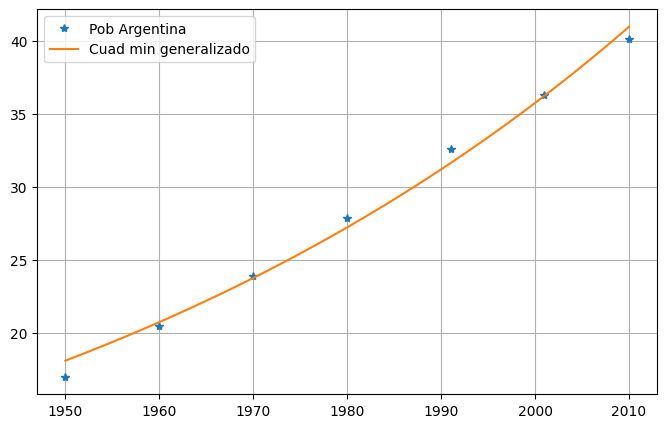

In [ ]:
# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

# tabla valores transformada para resolver por regresión lineal (ecuaciones normales)
# la tabla_x queda igual
tabla_z = np.log(tabla_y)

# pesos
pesos = tabla_y**2
W = np.diag(pesos)

# ecuaciones normales
fila_de_unos = np.ones(len(tabla_x))
A_traspuesta = np.array([fila_de_unos, tabla_x])
A = np.transpose(A_traspuesta)

coefs = np.linalg.solve(np.linalg.multi_dot([A_traspuesta,W,A]), np.linalg.multi_dot([A_traspuesta,W,tabla_z]))
print(coefs)

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
def cuad_min(x,a,b):
  y = a*np.exp(b*x)
  return y
a_monio = coefs[0]
b = coefs[1]
a = np.exp(a_monio)
vals_x_graficar = np.linspace(1950,2010, 5000)
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar,a,b), label='Cuad min generalizado')
plt.legend()
plt.grid()


# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x,a,b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

Error cuadrático medio: 0.48990303132111745


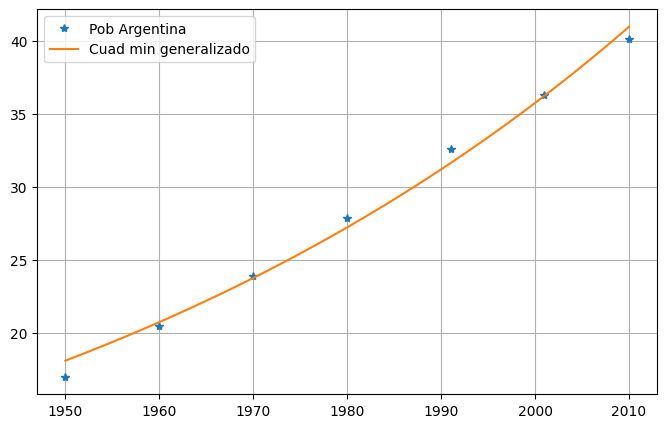

In [ ]:
# 4: todo lo anterior por numpy.polynomial

# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

# tabla valores transformada para resolver por regresión lineal (ecuaciones normales)
# la tabla_x queda igual
tabla_z = np.log(tabla_y)

# pesos para polyfit: SIN ELEVAR AL CUADRADO (los eleva al cuadrado numpy.polynomial)
pesos_para_numpy_polynomial = tabla_y

# cuad min por numpy.polynomial
grado = 1
cuad_min_por_polynomial = Poly.fit(tabla_x, tabla_z, deg=grado, w=pesos_para_numpy_polynomial)
coefs_por_polynomial = cuad_min_por_polynomial.convert().coef

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
a_monio = coefs[0]
b = coefs[1]
a = np.exp(a_monio)
def cuad_min_por_polynomial_transformado(x,a,b):
  y = a*np.exp(b*x)
  return y
vals_x_graficar = np.linspace(1950,2010, 5000)
plt.plot(vals_x_graficar, cuad_min_por_polynomial_transformado(vals_x_graficar,a,b), label='Cuad min generalizado')
plt.legend()
plt.grid()


# Error cuadrático medio
vals_y_cuad_min = cuad_min_por_polynomial_transformado(tabla_x,a,b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

---
---
# Levantar datos desde un archivo `.txt` o `.csv`, inspeccionarlos, graficarlos, y usarlos para mínimos cuadrados

## Librerías

In [ ]:
import numpy as np #para manejar arreglos
from matplotlib import pyplot as plt #para graficar

plt.rcParams["figure.figsize"] = (8,5) #tamaño de los gráficos: ancho x alto

import pandas as pd # para levantar datos desde archivos: txt, csv, otros.

In [ ]:
# el archivo debe estar en el mismo directorio que la NB Python
# para Google Colab hay que subir el archivo al Colab

# el df es por DataFrame de Pandas

# leemos el archivo
# nombre_archivo = 'infantesConBajoPesoAlNacer.txt'
nombre_archivo = 'humedad.csv'
datos_df = pd.read_table(nombre_archivo, sep=',')

#muestra primeras 5 filas, para inspeccionar a los datos
datos_df.head()

,t,humedad
0,1,80.334616
1,2,80.249820
2,3,80.448725
3,4,80.730281
4,5,80.940629


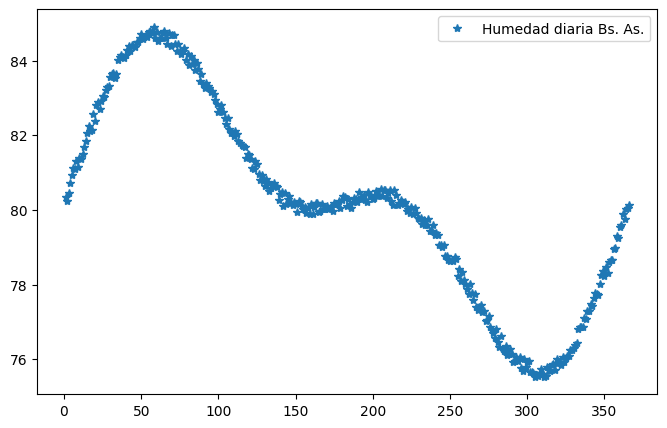

In [ ]:
# convertimos datos a numpy, porque somos numpyholics.
datos = datos_df.to_numpy()

# primer columna es día, segunda columna es humedad
dias = datos[:,0]
humedades = datos[:,1]

# graficamos
plt.plot(dias, humedades, '*', label='Humedad diaria Bs. As.')
plt.legend()

In [ ]:
# a partir de acá se puede armar la tabla de valores para trabajar como siempre por mínimos cuadrados

x = dias
y = humedades

# y como siempre mínimos cuadrados

---
---
# Regresión lineal múltiple
## Charlar la idea
## Mirar cuentas y Python de la teórica.